# CÂU 2

**MSSV:** 24133903  
**Họ tên:** Huỳnh Trung Nghĩa

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

data_path = 'Mag6PlusEarthquakes_1900-2013.xlsx'
earthquake = pd.read_excel(data_path, sheet_name='query')
earthquake.head()

,time,Date,Time,Unnamed: 3,latitude,longitude,depth,mag,magType,nst,gap,dmin,rms,net,id,updated,place,type
0,2014-03-17T05:11:34.980Z,2014-03-17,05:11:34,NaN,-20.0030,-70.8741,17.0,6.2,mww,NaN,82.0,1.171,1.37,us,usc000ndw9,2014-03-17T14:57:11.000Z,"80km WNW of Iquique, Chile",earthquake
1,2014-03-16T21:16:30.770Z,2014-03-16,21:16:30,NaN,-19.9246,-70.6278,20.0,6.7,mww,NaN,44.0,0.929,1.16,us,usc000ndnj,2014-03-17T18:43:29.249Z,"60km WNW of Iquique, Chile",earthquake
2,2014-03-15T23:51:30.610Z,2014-03-15,23:51:30,NaN,-5.5660,-80.8790,9.8,6.3,mwp,NaN,90.0,6.253,1.00,us,usc000nd0c,2014-03-18T17:52:18.000Z,"6km W of Sechura, Peru",earthquake
3,2014-03-15T08:59:21.790Z,2014-03-15,08:59:21,NaN,-14.0935,-76.2968,20.0,6.1,mww,NaN,71.0,2.159,1.02,us,usc000ncbl,2014-03-16T05:34:44.387Z,"25km S of Paracas, Peru",earthquake
4,2014-03-13T17:06:50.800Z,2014-03-13,17:06:50,NaN,33.6793,131.8197,79.0,6.3,mwb,NaN,14.0,0.963,1.26,us,usc000nabv,2014-03-17T23:24:32.491Z,"15km NNE of Kunisaki-shi, Japan",earthquake


## 1. Xử lý chuỗi và thời gian

### 1a

In [3]:
earthquake['Năm xảy ra động đất'] = pd.to_datetime(earthquake['Date']).dt.year
earthquake[['Date', 'Năm xảy ra động đất']].head()

,Date,Năm xảy ra động đất
0,2014-03-17,2014
1,2014-03-16,2014
2,2014-03-15,2014
3,2014-03-15,2014
4,2014-03-13,2014


### 1b

In [4]:
earthquake['Quốc gia/Khu vực chính'] = (
    earthquake['place']
    .astype('string')
    .str.split(',')
    .str[-1]
    .str.strip()
    .fillna('Không xác định')
)

earthquake[['place', 'Quốc gia/Khu vực chính']].head(10)

,place,Quốc gia/Khu vực chính
0,"80km WNW of Iquique, Chile",Chile
1,"60km WNW of Iquique, Chile",Chile
2,"6km W of Sechura, Peru",Peru
3,"25km S of Paracas, Peru",Peru
4,"15km NNE of Kunisaki-shi, Japan",Japan
5,"180km SE of Lorengau, Papua New Guinea",Papua New Guinea
6,East of the South Sandwich Islands,East of the South Sandwich Islands
7,"77km WNW of Ferndale, California",California
8,"262km ESE of Sola, Vanuatu",Vanuatu
9,"110km NW of Nago, Japan",Japan


Xử lý chuỗi lấy phần tử sau dấu phẩy cuối cùng. Với Place không có dấu phẩy, toàn bộ nội dung được giữ lại như một khu vực chính; giá trị thiếu được gán nhãn không xác định

## 2. Phân tích Fixed Level of Detail

### 2a

In [5]:
earthquake['Max_Magnitude_Of_Region'] = (
    earthquake
    .groupby('Quốc gia/Khu vực chính')['mag']
    .transform('max')
)

earthquake[[
    'Quốc gia/Khu vực chính',
    'mag',
    'Max_Magnitude_Of_Region'
]].head(10)

,Quốc gia/Khu vực chính,mag,Max_Magnitude_Of_Region
0,Chile,6.2,9.6
1,Chile,6.7,9.6
2,Peru,6.3,7.1
3,Peru,6.1,7.1
4,Japan,6.3,9.0
5,Papua New Guinea,6.1,8.1
6,East of the South Sandwich Islands,6.4,6.7
7,California,6.8,6.8
8,Vanuatu,6.3,7.9
9,Japan,6.5,9.0


transform('max') tạo giá trị cực đại theo từng khu vực nhưng vẫn giữ nguyên số dòng ban đầu. Đây là cách tương đương fixed lod trong pandas khi cần so sánh từng trận động đất với mức cực đại của nhóm.

### 2b

In [6]:
peak_earthquakes = earthquake[
    earthquake['mag'].eq(earthquake['Max_Magnitude_Of_Region'])
].copy()

peak_earthquakes[[
    'Date',
    'place',
    'Quốc gia/Khu vực chính',
    'mag',
    'Max_Magnitude_Of_Region'
]].sort_values('mag', ascending=False).head(20)

,Date,place,Quốc gia/Khu vực chính,mag,Max_Magnitude_Of_Region
6071,1960-05-22,"Araucania, Chile",Chile,9.6,9.6
5901,1964-03-28,Southern Alaska,Southern Alaska,9.2,9.2
1525,2004-12-26,off the west coast of northern Sumatra,off the west coast of northern Sumatra,9.1,9.1
470,2011-03-11,"near the east coast of Honshu, Japan",Japan,9.0,9.0
6396,1952-11-04,"off the east coast of the Kamchatka Peninsula,...",Russia,9.0,9.0
5841,1965-02-04,"Rat Islands, Aleutian Islands, Alaska",Alaska,8.7,8.7
1462,2005-03-28,"northern Sumatra, Indonesia",Indonesia,8.6,8.6
8160,1906-01-31,near the coast of Ecuador,near the coast of Ecuador,8.6,8.6
6716,1946-04-01,south of Alaska,south of Alaska,8.6,8.6
7081,1938-02-01,Banda Sea,Banda Sea,8.6,8.6


Danh sách trên gồm các bản ghi có 'mag' đúng bằng cực đại của khu vực tương ứng; nếu một khu vực có nhiều trận cùng đạt cực đại thì tất cả các bản ghi đó đều được giữ lại

## 3. Tính tỷ lệ và trực quan hóa đa chiều

### 3a

In [7]:
year_summary = (
    earthquake.groupby('Năm xảy ra động đất')
    .size()
    .reset_index(name='Số trận động đất')
    .sort_values('Năm xảy ra động đất')
)
year_summary = year_summary.assign(
    **{'Tỷ lệ (%)': year_summary['Số trận động đất'] / len(earthquake) * 100}
)
year_summary

,Năm xảy ra động đất,Số trận động đất,Tỷ lệ (%)
0,1900,21,0.252616
1,1901,27,0.324792
2,1902,30,0.360881
3,1903,18,0.216528
4,1904,20,0.240587
...,...,...,...
110,2010,174,2.093107
111,2011,207,2.490076
112,2012,133,1.599904
113,2013,143,1.720197


Tỷ lệ của mỗi năm được tính bằng số trận động đất trong năm chia cho tổng số bản ghi trong toàn bộ lịch sử dữ liệu, sau đó nhân 100

### 3b

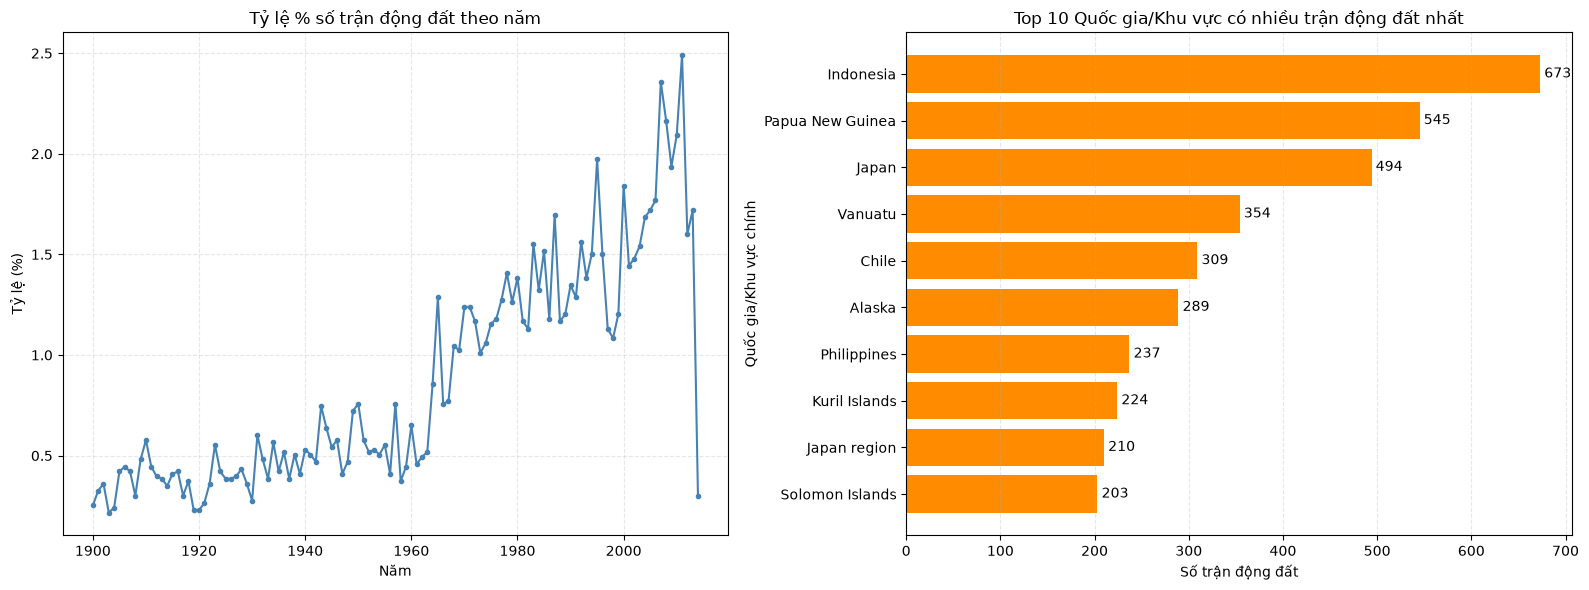

In [8]:
region_summary = (
    earthquake.groupby('Quốc gia/Khu vực chính')
    .size()
    .reset_index(name='Số trận động đất')
)
top_10_regions = (
    region_summary.nlargest(10, 'Số trận động đất')
    .sort_values('Số trận động đất')
)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].plot(
    year_summary['Năm xảy ra động đất'],
    year_summary['Tỷ lệ (%)'],
    color='steelblue',
    marker='o',
    linewidth=1.5,
    markersize=3
)
axes[0].set_title('Tỷ lệ % số trận động đất theo năm')
axes[0].set_xlabel('Năm')
axes[0].set_ylabel('Tỷ lệ (%)')
axes[0].grid(True, linestyle='--', alpha=0.3)

bars = axes[1].barh(
    top_10_regions['Quốc gia/Khu vực chính'],
    top_10_regions['Số trận động đất'],
    color='darkorange'
)
axes[1].bar_label(bars, fmt='%.0f', padding=3)
axes[1].set_title('Top 10 Quốc gia/Khu vực có nhiều trận động đất nhất')
axes[1].set_xlabel('Số trận động đất')
axes[1].set_ylabel('Quốc gia/Khu vực chính')
axes[1].grid(axis='x', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

Nhận xét: Biểu đồ đường cho thấy mức độ biến động của hoạt động động đất theo thời gian; biểu đồ thanh ngang xếp hạng trực tiếp các khu vực có tần suất xuất hiện cao nhất. Thanh ngang được sắp xếp tăng dần để khu vực đứng đầu dễ nhận diện